In [72]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path

PROJECT_ROOT=Path.cwd().parent
DATASET_DIR=PROJECT_ROOT / 'datasets' / 'Credit-Card-Data'

df=pd.read_csv(DATASET_DIR / 'creditcard.csv')

In [73]:
df.sample(10)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
153297,98478.0,-0.912157,0.175658,0.212420,1.235652,2.400864,0.354079,1.058284,-0.264514,0.688737,...,0.013111,0.968023,0.427887,-1.069275,-0.117300,-0.350702,0.012677,-0.104792,6.76,0
16190,27608.0,-0.504043,0.054746,0.689731,-2.088511,0.417555,-0.299248,0.309941,0.021371,-1.520624,...,0.299962,0.743903,-0.244649,-0.797033,0.101200,-0.270706,0.335486,0.187314,40.85,0
138563,82728.0,0.799530,-1.861397,0.719561,-1.770426,-1.373863,1.198547,-1.138485,0.505280,1.076680,...,-0.302179,-0.307267,0.093459,-0.621391,-0.128598,0.007363,0.111812,0.048249,188.60,0
233736,147684.0,1.997776,-0.662821,-0.631958,-1.393261,-0.879245,-1.249351,-0.325364,-0.273472,1.955280,...,-0.195004,-0.370413,0.332254,0.060346,-0.395048,-0.569583,0.026923,-0.030363,38.67,0
121346,76157.0,1.020244,-0.303081,1.215219,1.620950,-0.737809,0.907879,-0.687964,0.481975,1.129959,...,-0.369529,-0.687157,0.075466,0.000682,0.361965,-0.524817,0.079904,0.018034,18.99,0
28358,34970.0,-1.973004,0.748433,1.254419,-2.276531,-0.077814,0.539931,-0.028845,0.474685,2.103192,...,-0.208863,0.041617,-0.357367,-1.330955,0.721771,-0.740563,-0.646160,-0.598687,13.29,0
280213,169390.0,-4.943048,-1.737308,-2.383794,-2.419437,-1.763427,0.123365,-2.212334,1.158355,-2.126686,...,0.590261,-0.658585,-0.874144,-0.292417,-0.222255,-0.311623,-0.407338,-1.140719,87.49,0
17631,28833.0,-0.350597,-0.387388,2.518587,-1.396596,-0.729816,-0.092687,-0.222228,-0.357812,-0.381496,...,0.403245,1.447425,-0.364475,-0.066165,-0.343860,-0.147965,-0.236658,-0.332048,49.99,0
226544,144681.0,-0.469536,0.430368,0.428382,-0.671991,0.449392,0.089054,1.719430,-0.488114,0.075944,...,0.090204,0.650709,-0.256432,0.682104,-0.058197,0.515782,-0.116644,-0.117776,164.00,0
60518,49360.0,-0.774316,1.381433,1.629710,0.424012,0.854930,-0.221258,1.654067,-1.109168,0.923407,...,-0.177734,0.654285,-0.297991,0.072145,-0.278160,-0.442110,-0.346253,-0.705660,2.63,0


In [74]:
df['Class'].value_counts(normalize=True), df['Class'].value_counts()

(Class
 0    0.998273
 1    0.001727
 Name: proportion, dtype: float64,
 Class
 0    284315
 1       492
 Name: count, dtype: int64)

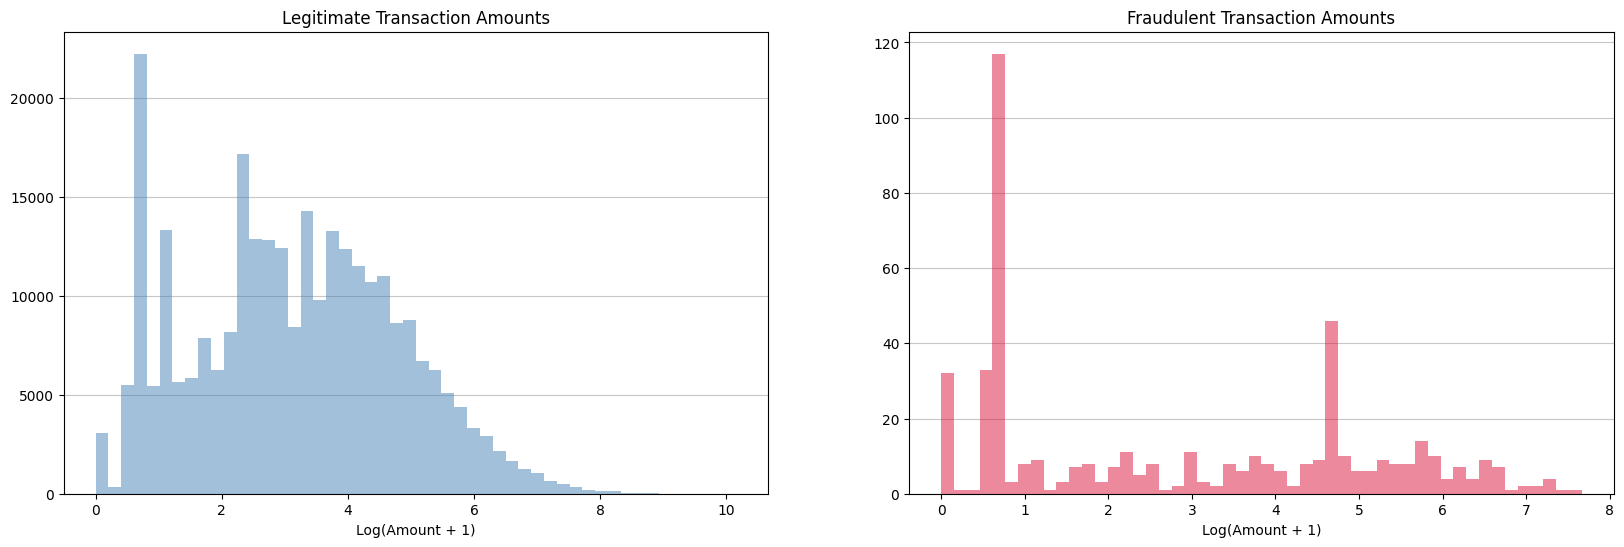

In [77]:
fig, axs = plt.subplots(1, 2, figsize=(20,6))
axs[0].hist(np.log1p(df[df['Class'] == 0]['Amount']), bins=50, color='steelblue', alpha=0.5)
axs[0].set_title('Legitimate Transaction Amounts')
axs[0].set_xlabel('Log(Amount + 1)')
axs[0].grid(axis='y', alpha=0.7)
axs[0].set_axisbelow(True)

axs[1].hist(np.log1p(df[df['Class'] == 1]['Amount']), bins=50, color='crimson', alpha=0.5)
axs[1].set_title('Fraudulent Transaction Amounts')
axs[1].set_xlabel('Log(Amount + 1)')
axs[1].grid(axis='y', alpha=0.7)
axs[1].set_axisbelow(True)
plt.show()

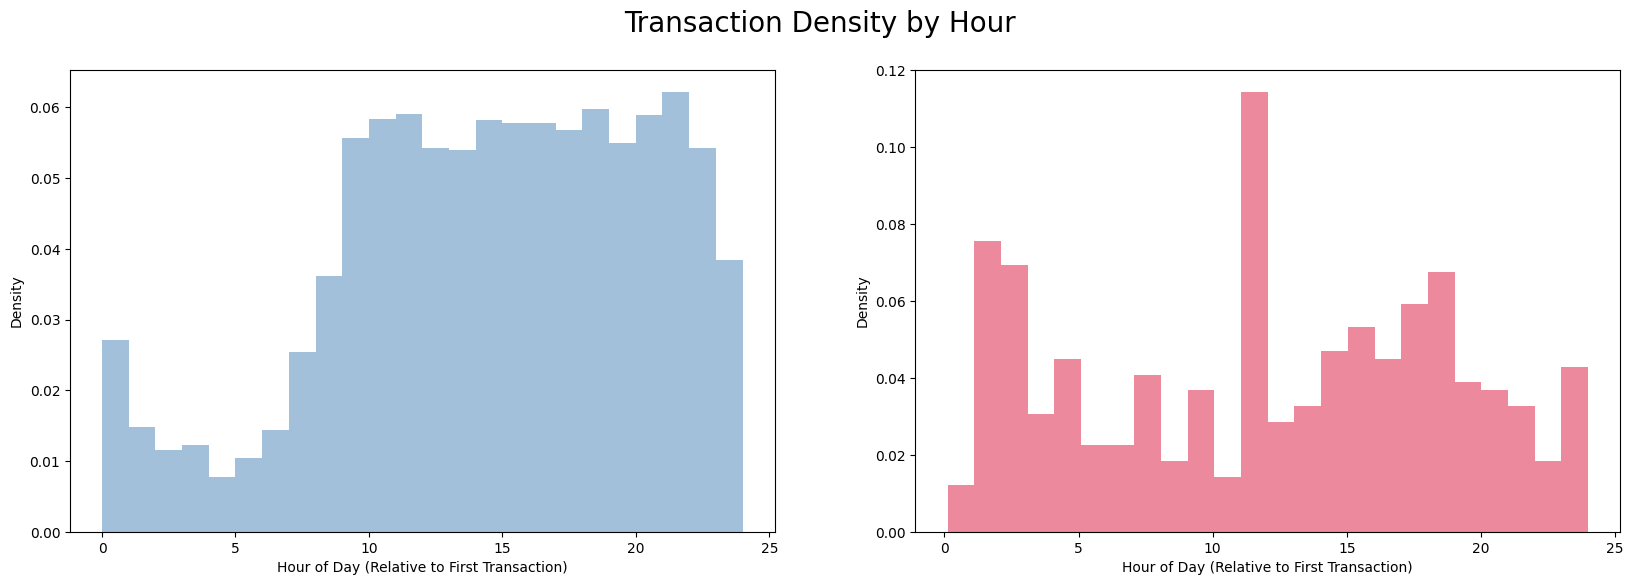

In [76]:
df['Hour'] = (df['Time'] / 3600) % 24
fig, ax = plt.subplots(1, 2, figsize=(20, 6))
ax[0].hist(df[df['Class'] == 0]['Hour'], bins=24, density=True, alpha=0.5, label='Legitimate', color='steelblue')
ax[0].set_xlabel('Hour of Day (Relative to First Transaction)')
ax[0].set_ylabel('Density')

ax[1].hist(df[df['Class'] == 1]['Hour'], bins=24, density=True, alpha=0.5, label='Fraud', color='crimson')
ax[1].set_xlabel('Hour of Day (Relative to First Transaction)')
ax[1].set_ylabel('Density')

fig.suptitle('Transaction Density by Hour', fontsize=20)
plt.show()